In [13]:
from the_well.benchmark.metrics.spatial import VRMSE
import matplotlib.pyplot as plt
from einops import rearrange
import seaborn as sns
import pandas as pd
import numpy as np
import pickle
import torch
import math
import sys

rc = {
    "axes.axisbelow": True,
    "axes.linewidth": 1.0,
    "axes.labelsize": "x-small",
    "axes.titlesize": "x-small",
    "figure.dpi": 150,
    "figure.figsize": (3.2, 3.2),
    "font.size": 12.0,
    "legend.fontsize": "xx-small",
    "lines.linewidth": 1.0,
    "savefig.transparent": True,
    "xtick.labelsize": "xx-small",
    "xtick.major.width": 1.0,
    "ytick.labelsize": "xx-small",
    "ytick.major.width": 1.0,
    "font.family": ["serif"],
    "text.usetex": True,
    "text.latex.preamble": r"\usepackage{amsfonts}",
}

plt.rcParams.update(rc)

PROJECT_ROOT = "/Users/gabrieleaccarino/Workspace/waveletflux"
sys.path.insert(0, PROJECT_ROOT)

from waveletflux.utils.eval import build_stats_df, build_psd_df
from waveletflux.utils.plot import plot_psd, plot_psd_seaborn
from waveletflux.utils.well_data import get_well_dataset

device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")

outdir = f'{PROJECT_ROOT}/figures'

# Get Dataset

In [14]:
well_base_path    = '/Users/gabrieleaccarino/Workspace/multi-scale-wavelet-flow-matching/data/datasets'
well_dataset_name = 'turbulent_radiative_layer_2D'

dataset = get_well_dataset(
    path=well_base_path,
    physics=well_dataset_name,
    split='test',
    steps=-1,          # loads full trajectory
)

meta_field_names = dataset.metadata.field_names
field_names = [item for sublist in meta_field_names.values() for item in sublist]

# Load predictions

In [15]:
RESULT_DIR = f"/Users/gabrieleaccarino/Workspace/waveletflux/experiments/{well_dataset_name}/results"

model_paths = {
    "WaveletFM-1scale"          : f'{RESULT_DIR}/WaveletFlow_{well_dataset_name}_1scales_db2_rollout_nsampling_steps20_nensemble1_traj.pkl',
    #"WaveletFM-3scales"         : f'{RESULT_DIR}/WaveletFlow_{well_dataset_name}_3scales_db2_rollout_nsampling_steps20_nensemble1_traj.pkl',
    #"WaveletFM-3scales"         : f'{RESULT_DIR}/WaveletFlow_{well_dataset_name}_3scales_db2_v3.0_rollout_nsampling_steps20_nensemble1_traj.pkl',
    "WaveletFM-3scales"    : f'{RESULT_DIR}/WaveletFlow_{well_dataset_name}_3scales_db2_last_v3.0_rollout_nsampling_steps20_nensemble1_traj.pkl',
    "UNetClassic"               : f'{RESULT_DIR}/UNetClassic_{well_dataset_name}_rollout_traj.pkl',
    #"UNetConvNext"              : f'{RESULT_DIR}/UNetConvNext_{well_dataset_name}_rollout_traj.pkl',
}

generative_models = ["WaveletFM-1scale", "WaveletFM-3scales", "WaveletFM-3scales-last"]

# model data
rollout_traj = {}
for model, path in model_paths.items():
    with open(path, 'rb') as f:
        rollout_traj[model] = pickle.load(f)

# ground truth data
with open(f'{RESULT_DIR}/ground_truth_{well_dataset_name}_traj.pkl', 'rb') as f:
    truth_traj = pickle.load(f)

# Configuration

In [16]:
Ti = 4 # number of initial steps to skip (models start from these, so they are not predictions)

#lead_times = [1, 16, 32, 48, 64, 80, 96]

predictions = {
    "WaveletFM-1scale"       : rollout_traj["WaveletFM-1scale"],   
    #"WaveletFM-3scales"      : rollout_traj["WaveletFM-3scales"],  
    "WaveletFM-3scales"      : rollout_traj["WaveletFM-3scales"],    
    "UNetClassic"            : rollout_traj["UNetClassic"],        
    #"UNetConvNext"           : rollout_traj["UNetConvNext"],       
}

palette = sns.cubehelix_palette(len(predictions.keys()), start=2, dark=0.25)
#palette = sns.cubehelix_palette(len(table["model"].unique()), dark=0.25)
palette

[[0.8474590274530256, 0.8341308330637194, 0.9509595675385358],
 [0.4222025813968738, 0.5859841229046691, 0.6966196354229758],
 [0.11649760470158971, 0.31640224728208166, 0.26685137860728414]]

# Evaluation Metrics

In [17]:
aggregate_mode = "mean"

def horizon(t):
    if t < 20:
        return "01:33"
    elif t < 60:
        return "34:65"
    elif t < 100:
        return "66:97"
    else:
        return "101:180"
    
def aggregate(x):
    if "mean" in aggregate_mode:
        return np.mean(x)
    elif "median" in aggregate_mode:
        return np.median(x)

def model_type(model):
    if model in generative_models:
        return "generative"
    return "deterministic"

# Build Stats DataFrame

In [18]:
df = build_stats_df(
    truth        = truth_traj,  
    predictions  = predictions,
    field_names  = field_names,
    Ti           = Ti,
    lead_times   = None,
    stride       = 1,
)

df["horizon"] = df["time"].apply(horizon)
df["model_type"] = df["model"].apply(model_type)

In [19]:
df.columns

Index(['model', 'traj', 'field', 'step', 'time', 'm1', 'm2', 'spread', 'rmse',
       'nrmse', 'vrmse', 'spread_skill', 'total_error', 'rmse_p_low',
       'rmse_c_low', 'rmse_p_mid', 'rmse_c_mid', 'rmse_p_high', 'rmse_c_high',
       'horizon', 'model_type'],
      dtype='object')

In [20]:
summary = (
    df.groupby(["model", "field"])[["vrmse", "rmse_p_low", "rmse_p_mid", "rmse_p_high"]]
    .mean()
    .round(4)
)
print(summary.to_string())

                               vrmse  rmse_p_low  rmse_p_mid  rmse_p_high
model             field                                                  
UNetClassic       density     0.6905      0.4928      0.6300       0.2467
                  pressure    2.7890     15.5413      6.1723       2.7366
                  velocity_x  1.2228      0.6483      0.5059       0.3165
                  velocity_y  1.3294      2.0915      1.2852       1.5355
WaveletFM-1scale  density     0.4271      0.2269      0.2802       0.1615
                  pressure    1.5892      1.1516      0.7362       0.3563
                  velocity_x  0.4876      0.3428      0.4056       0.1777
                  velocity_y  0.9477      0.7782      0.5534       0.3426
WaveletFM-3scales density     0.4241      0.2427      0.2451       0.1371
                  pressure    1.7405      1.8649      2.2963       0.4813
                  velocity_x  0.5342      0.5489      0.5111       0.2270
                  velocity_y  1.0327  

In [ ]:
#summary.style.apply(highlight_min_per_field_horizon, axis=None).format(precision=3)

# Plot: VRMSE at different rollout steps/regimes

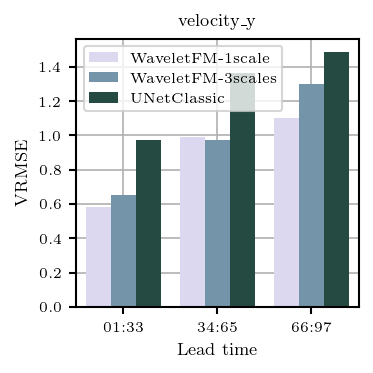

In [26]:
%matplotlib inline

field = 'velocity_y'

table = df[df["field"] == field]

fig = plt.figure(figsize=(2.4, 2.4))

ax = sns.barplot(
    table,
    x="horizon",
    y="vrmse",
    hue="model",
    estimator=aggregate,
    errorbar=None,
    palette=palette, #sns.cubehelix_palette(5, dark=0.25)[1:],
)

ax.grid()
ax.get_legend().set_title(None)

ax.set_xlabel("Lead time")
ax.set_ylabel("VRMSE")
ax.set_title(field)

fig.tight_layout(pad=0.33)

plt.savefig(f"{outdir}/vrmse_rollout_{field}.png", dpi=300, transparent=True)
plt.show()

# Plot: Averaged Power Spectrum RMSE across test trajectories

In [ ]:
table = df

fig, axs = plt.subplot_mosaic(
    [[0], [1], [2]],
    figsize=(3.2, 4.8),
    sharex=True,
    sharey=False,
)

# solid for generative, dashed for deterministic
dashes  = {"generative": (1, 0), "deterministic": (4, 2)}

for i, band in enumerate(["Low", "Mid", "High"]):
    ax = sns.lineplot(
        table,
        x="time",
        y=f"rmse_p_{band.lower()}",
        hue="model",
        style="model_type",
        dashes=dashes,
        estimator=aggregate,
        errorbar=None,
        palette=palette,
        ax=axs[i],
    )
    ax.grid(alpha=0.3)

    ax.set_xlabel("Lead time" if i == 2 else "")
    ax.set_xlim(-5, 101)

    ax.set_ylabel(band)
    ax.set_ylim(-0.05, 0.7)

    ax.tick_params(direction="in")
    ax.yaxis.set_label_position("right")
    ax.yaxis.label.set(rotation=-90, va="center")
    ax.yaxis.tick_right()

    if i == 0:
        ax.set_title("Power Spectrum RMSE")
        handles, labels = ax.get_legend_handles_labels()
    ax.get_legend().remove()

# ── Clean up legend: remove the "model_type" section header ───────────────────
clean = [(h, l) for h, l in zip(handles, labels) if l not in ("model_type", "generative", "deterministic", "model")]
handles_clean, labels_clean = zip(*clean)

fig.align_labels()
fig.tight_layout(pad=0.33)
fig.subplots_adjust(bottom=0.18)  # make room at the bottom
fig.legend(handles_clean, labels_clean, loc="lower center", ncol=2, fontsize=8, bbox_to_anchor=(0.45, 0.02))
plt.show()

# Plot PSD

In [ ]:
psd_df = build_psd_df(
    truth = truth_traj,
    predictions = predictions,
    field_names = field_names,
    Ti = Ti,
    lead_times = None,
    stride = 1,      
    min_bin_count = 3,   
)

In [ ]:
psd_df

In [ ]:
fig = plot_psd_seaborn(
    psd_df=psd_df,
    field_names=field_names,
    agg_over=["traj", "ens", "step"],
    gt_label="Ground-truth",
    palette=palette,
    gt_color="black",
    gt_lw=1.5,
    model_lw=1.0,
    ci=None,
    figsize=(4.0, 3.5),
    log_base=2,
)

# PSD Plot from LOLA (select traj + ens + specific step in the trajectory)

In [ ]:
x = truth_traj[0, ...]
x = rearrange(x, "steps h w c -> c steps h w")
y = predictions['WaveletFM-3scales-last'][0, 0, ...]
y = predictions['WaveletFM-1scale'][0, 0, ...]
y = predictions['UNetClassic'][0, ...]
y = rearrange(y, "steps h w c -> c steps h w")

print(x.shape, y.shape)


plot_psd(
    x = x[:, 64],
    y = y[:, 64],
    fields = field_names,  
)

# Tables 

In [ ]:
table = df[["model", "field", "horizon", "vrmse"]]

table = table.groupby(["model", "field", "horizon"]).agg(aggregate).round(3).reset_index()
table = table.pivot(index=["model", "field"], columns="horizon", values=["vrmse"])
# print(table.to_latex(float_format="%.3f"))
table

In [ ]:
import pandas as pd

def highlight_min_per_field_horizon(df: pd.DataFrame) -> pd.DataFrame:
    styles = pd.DataFrame("", index=df.index, columns=df.columns)

    fields = df.index.get_level_values("field").unique()

    for field, color in zip(fields, palette):
        r, g, b = [int(c * 255) for c in color[:3]]
        css = f"background-color: rgb({r},{g},{b}); color: white; font-weight: bold"

        field_mask = df.index.get_level_values("field") == field
        sub = df.loc[field_mask]           # rows for this field, all models

        for col in df.columns:
            min_idx = sub[col].idxmin()    # (model, field) index of the min
            styles.loc[min_idx, col] = css

    return styles

In [ ]:
table.style.apply(highlight_min_per_field_horizon, axis=None).format(precision=3)